In [3]:
import os
import pandas as pd

# ============================================================
# Paths
# ============================================================
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_combinations.csv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles"
OUTFILE = os.path.join(OUTDIR, "all_single_site_counts.tsv")

os.makedirs(OUTDIR, exist_ok=True)

# ============================================================
# Load metadata
# ============================================================
meta = pd.read_csv(META_FILE)

# Clean columns
meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()

# Remove missing / empty values if any
meta = meta[
    meta["id"].notna() &
    meta["metastatic_sites"].notna() &
    (meta["metastatic_sites"] != "") &
    (meta["metastatic_sites"] != "nan")
].copy()

# ============================================================
# Count samples per single metastatic site
# ============================================================
site_counts = (
    meta["metastatic_sites"]
    .value_counts()
    .rename_axis("site")
    .reset_index(name="n_samples")
)

# ============================================================
# Print result
# ============================================================
print("\nAll single metastatic site counts:\n")
print(site_counts.to_string(index=False))

# ============================================================
# Save result
# ============================================================
site_counts.to_csv(OUTFILE, sep="\t", index=False)

print(f"\nSaved: {OUTFILE}")


All single metastatic site counts:

                      site  n_samples
                     liver         53
                     brain         19
                      bone         17
                        ln         10
                      lung          5
                    breast          5
                chest wall          4
                    pleura          4
                     spine          3
          pleural effusion          2
contralateral right axilla          1
                     skull          1
                    kidney          1
                recurrence          1
                   omentum          1

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/all_single_site_counts.tsv


In [5]:
import os
import glob
import pandas as pd
from functools import reduce

# ============================================================
# Paths
# ============================================================
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_combinations.csv"
CNR_DIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNVKit/Annotated_cnr_file"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles"
OUTFILE = os.path.join(OUTDIR, "combined_top3sites_1Mb_cnr_wide.tsv")

os.makedirs(OUTDIR, exist_ok=True)

# ============================================================
# Fixed top 3 sites
# ============================================================
FOCUS_SITES = ["liver", "brain", "bone"]

CHR_ORDER = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

# ============================================================
# Load metadata
# ============================================================
meta = pd.read_csv(META_FILE)

meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()

meta = meta[
    meta["id"].notna() &
    meta["metastatic_sites"].notna() &
    (meta["metastatic_sites"] != "") &
    (meta["metastatic_sites"] != "nan")
].copy()

meta = meta[meta["metastatic_sites"].isin(FOCUS_SITES)].copy()

# sample -> site mapping
sample_to_site = dict(zip(meta["id"], meta["metastatic_sites"]))

print("\nSelected sample counts:")
print(meta["metastatic_sites"].value_counts())

# ============================================================
# Build wide matrix
# ============================================================
merge_keys = ["chromosome", "start", "end", "gene"]

sample_dfs = []
missing_files = []

for sample_id in sorted(sample_to_site.keys()):
    cnr_file = os.path.join(CNR_DIR, f"{sample_id}.annotated.cnr")

    if not os.path.exists(cnr_file):
        missing_files.append(sample_id)
        continue

    df = pd.read_csv(cnr_file, sep="\t")

    # Required shared columns
    required_shared = ["chromosome", "start", "end", "gene", "log2"]
    for col in required_shared:
        if col not in df.columns:
            raise ValueError(f"Missing required column '{col}' in {cnr_file}")

    # Sample-specific columns
    call_col = f"{sample_id}.Corrected_Call"
    copy_col = f"{sample_id}.Corrected_Copy_Number"

    if call_col not in df.columns:
        raise ValueError(f"Missing column '{call_col}' in {cnr_file}")
    if copy_col not in df.columns:
        raise ValueError(f"Missing column '{copy_col}' in {cnr_file}")

    sub = df[["chromosome", "start", "end", "gene", "log2", call_col, copy_col]].copy()

    # Rename log2 to sample-specific column
    sub = sub.rename(columns={
        "log2": f"{sample_id}.log2"
    })

    # Keep chromosome order clean later
    sub["start"] = pd.to_numeric(sub["start"], errors="coerce")
    sub["end"] = pd.to_numeric(sub["end"], errors="coerce")

    sample_dfs.append(sub)

# ============================================================
# Check files
# ============================================================
print(f"\nSamples expected from metadata: {len(sample_to_site)}")
print(f"Samples loaded from .cnr files: {len(sample_dfs)}")
print(f"Missing .cnr files: {len(missing_files)}")

if missing_files:
    print("\nMissing sample files:")
    for s in missing_files:
        print(s)

if len(sample_dfs) == 0:
    raise ValueError("No .annotated.cnr files were loaded.")

# ============================================================
# Merge all sample tables on shared genomic coordinates
# ============================================================
wide_df = reduce(
    lambda left, right: pd.merge(left, right, on=merge_keys, how="outer"),
    sample_dfs
)

# ============================================================
# Sort rows by chromosome/start/end
# ============================================================
chr_order_map = {chrom: i for i, chrom in enumerate(CHR_ORDER)}

wide_df["chr_order"] = wide_df["chromosome"].map(chr_order_map)
wide_df = wide_df.sort_values(["chr_order", "start", "end"]).drop(columns=["chr_order"]).reset_index(drop=True)

# ============================================================
# Save result
# ============================================================
wide_df.to_csv(OUTFILE, sep="\t", index=False)

# ============================================================
# Print result summary
# ============================================================
print("\nWide matrix preview:")
print(wide_df.iloc[:5, :12].to_string(index=False))

print("\nSaved file:")
print(OUTFILE)

print(f"Rows    : {wide_df.shape[0]}")
print(f"Columns : {wide_df.shape[1]}")

# Expected columns:
# 4 shared columns + 3 columns per loaded sample
expected_cols = 4 + (3 * len(sample_dfs))
print(f"Expected columns final: {expected_cols}")



Selected sample counts:
liver    53
brain    19
bone     17
Name: metastatic_sites, dtype: int64

Samples expected from metadata: 89
Samples loaded from .cnr files: 89
Missing .cnr files: 0


/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:119: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead.  To get a de-fragmented frame, use `newframe = frame.copy()`



Wide matrix preview:
chromosome   start     end                                                                                                                                                                             gene  TP18-M578.log2 TP18-M578.Corrected_Call  TP18-M578.Corrected_Copy_Number  TP18-M624.log2 TP18-M624.Corrected_Call  TP18-M624.Corrected_Copy_Number  TP18-M677.log2 TP18-M677.Corrected_Call
      chr1 3000001 4000000                        ACTRT2,PRDM16-DT,PRDM16,MIR4251,ARHGEF16,MEGF6,MIR551A,TPRG1L,WRAP73,TP73,TP73-AS1,CCDC27,SMIM1,LRRC47,CEP104,DFFB,C1orf174,LINC01134,LINC01346,LINC01345          0.0733                     HETD                                1          0.0171                     NEUT                                2         -0.0272                     NEUT
      chr1 4000001 5000000                                                                                                                                                        LINC01777,LINC

In [11]:
import pandas as pd

# ============================================================
# Path to wide CNV matrix
# ============================================================
WIDE_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/combined_top3sites_1Mb_cnr_wide.tsv"

# ============================================================
# Load wide matrix
# ============================================================
wide = pd.read_csv(WIDE_FILE, sep="\t")

# ============================================================
# Get sample names from *.log2 columns
# ============================================================
log2_cols = [c for c in wide.columns if c.endswith(".log2")]
samples = sorted([c[:-5] for c in log2_cols])  # remove ".log2"

print("Total samples found:", len(samples))
print()

# ============================================================
# Print Corrected_Call distribution for first 5 samples
# ============================================================
for sample in samples[:5]:
    call_col = f"{sample}.Corrected_Call"

    if call_col not in wide.columns:
        print(f"{sample}: missing column {call_col}")
        print()
        continue

    print(sample)
    print(
        wide[call_col]
        .dropna()
        .astype(str)
        .str.upper()
        .value_counts()
        .head(10)
    )
    print()

Total samples found: 89

TP18-M578
NEUT     1560
HETD      462
GAIN      461
HLAMP      95
AMP        23
Name: TP18-M578.Corrected_Call, dtype: int64

TP18-M624
NEUT    1721
GAIN     460
HETD     420
Name: TP18-M624.Corrected_Call, dtype: int64

TP18-M677
NEUT    2518
HETD      83
Name: TP18-M677.Corrected_Call, dtype: int64

TP18-M772
NEUT    2407
GAIN     143
HETD      51
Name: TP18-M772.Corrected_Call, dtype: int64

TP19-M210
NEUT    2601
Name: TP19-M210.Corrected_Call, dtype: int64




Samples found in wide matrix and metadata:
89

Collapsed call counts for first 5 samples:

TP18-M578
NEUTRAL    1560
GAIN        579
LOSS        462
Name: TP18-M578.Corrected_Call, dtype: int64

TP18-M624
NEUTRAL    1721
GAIN        460
LOSS        420
Name: TP18-M624.Corrected_Call, dtype: int64

TP18-M677
NEUTRAL    2518
LOSS         83
Name: TP18-M677.Corrected_Call, dtype: int64

TP18-M772
NEUTRAL    2407
GAIN        143
LOSS         51
Name: TP18-M772.Corrected_Call, dtype: int64

TP19-M210
NEUTRAL    2601
Name: TP19-M210.Corrected_Call, dtype: int64


Sample-level CNV burden preview:

   sample  site  n_bins  n_gain_bins  n_loss_bins  n_altered_bins  gain_fraction  loss_fraction      fga  mean_log2  mean_abs_log2  median_abs_log2
TP18-M578 liver    2601          579          462            1041       0.222607       0.177624 0.400231   0.003992       0.051211           0.0385
TP18-M624 liver    2601          460          420             880       0.176855       0.161476 0.338331 

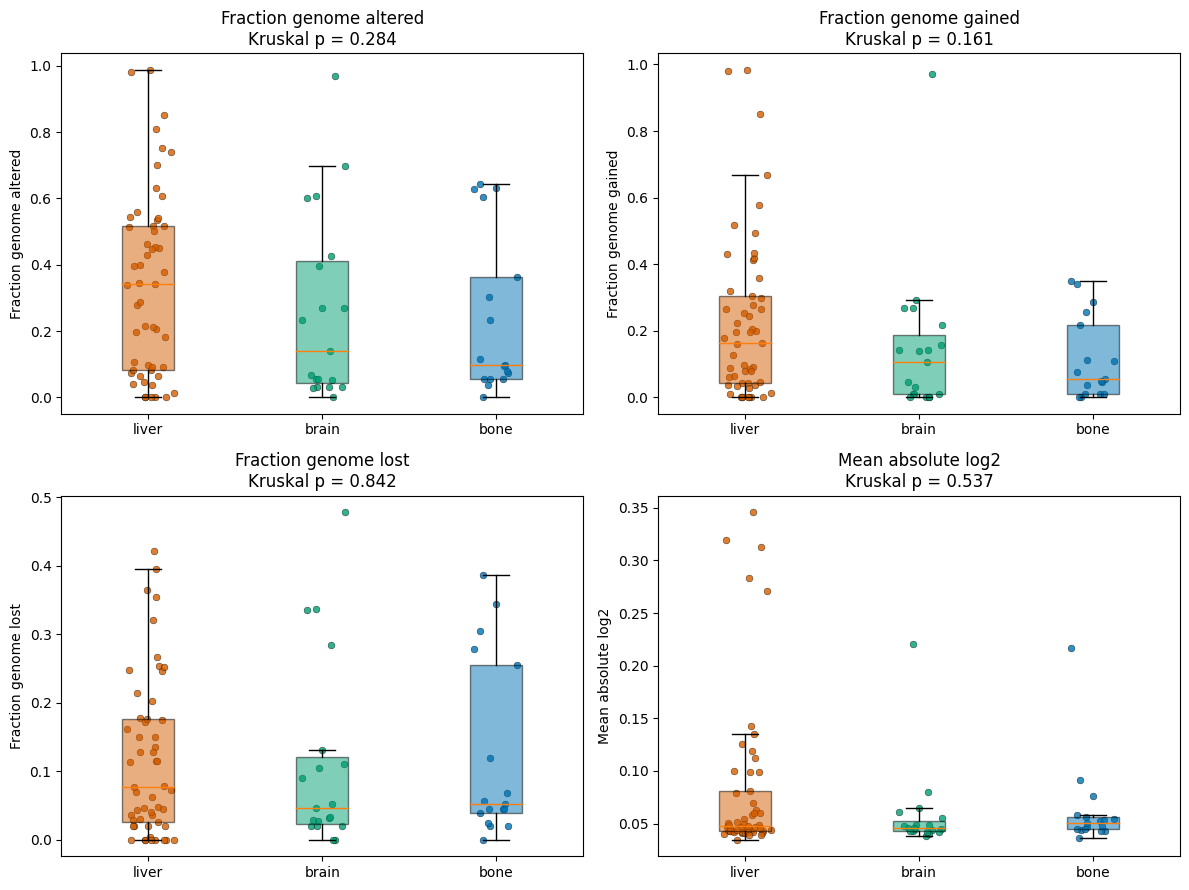


Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/sample_level_CNV_burden.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/sample_level_CNV_burden_global_stats.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/sample_level_CNV_burden_pairwise_stats.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/sample_level_CNV_burden.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/sample_level_CNV_burden.pdf


In [1]:
# Global CNV burden across sites
import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu

# ============================================================
# Paths
# ============================================================
WIDE_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/combined_top3sites_1Mb_cnr_wide.tsv"
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_combinations.csv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles"

os.makedirs(OUTDIR, exist_ok=True)

OUT_BURDEN   = os.path.join(OUTDIR, "sample_level_CNV_burden.tsv")
OUT_GLOBAL   = os.path.join(OUTDIR, "sample_level_CNV_burden_global_stats.tsv")
OUT_PAIRWISE = os.path.join(OUTDIR, "sample_level_CNV_burden_pairwise_stats.tsv")
OUT_PNG      = os.path.join(OUTDIR, "sample_level_CNV_burden.png")
OUT_PDF      = os.path.join(OUTDIR, "sample_level_CNV_burden.pdf")

# ============================================================
# Settings
# ============================================================
FOCUS_SITES = ["liver", "brain", "bone"]
SITE_ORDER = ["liver", "brain", "bone"]

SITE_COLORS = {
    "liver": "#D55E00",
    "brain": "#009E73",
    "bone":  "#0072B2"
}

METRICS_FOR_STATS = [
    "gain_fraction",
    "loss_fraction",
    "fga",
    "mean_abs_log2"
]

# ============================================================
# Helper functions
# ============================================================
def bh_adjust(pvals):
    """Benjamini-Hochberg FDR correction."""
    pvals = np.array(pvals, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]
    adj = np.empty(n, dtype=float)

    prev = 1.0
    for i in range(n - 1, -1, -1):
        rank = i + 1
        val = ranked[i] * n / rank
        prev = min(prev, val)
        adj[i] = prev

    out = np.empty(n, dtype=float)
    out[order] = np.minimum(adj, 1.0)
    return out

def parse_samples_from_wide(df):
    log2_cols = [c for c in df.columns if c.endswith(".log2")]
    samples = [c[:-5] for c in log2_cols]  # remove ".log2"
    return samples

def safe_numeric(series):
    return pd.to_numeric(series, errors="coerce")

def clean_call(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().upper()

    # Gains
    if x in {"GAIN", "AMP", "HLAMP", "AMPLIFICATION"}:
        return "GAIN"

    # Losses / deletions
    if x in {"LOSS", "DEL", "HETD", "HOMD", "DELETION"}:
        return "LOSS"

    # Neutral
    if x in {"NEUT", "NEUTRAL"}:
        return "NEUTRAL"

    return x

def add_jitter(n, scale=0.06, seed=123):
    rng = np.random.default_rng(seed)
    return rng.normal(0, scale, n)

# ============================================================
# Load files
# ============================================================
wide = pd.read_csv(WIDE_FILE, sep="\t")
meta = pd.read_csv(META_FILE)

meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()
meta = meta[meta["metastatic_sites"].isin(FOCUS_SITES)].copy()

sample_to_site = dict(zip(meta["id"], meta["metastatic_sites"]))

samples = parse_samples_from_wide(wide)

# Keep only samples that are both in wide matrix and metadata
samples = [s for s in samples if s in sample_to_site]

print("\nSamples found in wide matrix and metadata:")
print(len(samples))

# ============================================================
# Quick sanity check: collapsed calls for first few samples
# ============================================================
print("\nCollapsed call counts for first 5 samples:\n")
for sample in samples[:5]:
    call_col = f"{sample}.Corrected_Call"
    if call_col in wide.columns:
        print(sample)
        print(wide[call_col].apply(clean_call).value_counts(dropna=False))
        print()

# ============================================================
# Compute sample-level burden
# ============================================================
rows = []

for sample in samples:
    log2_col = f"{sample}.log2"
    call_col = f"{sample}.Corrected_Call"

    if log2_col not in wide.columns:
        continue
    if call_col not in wide.columns:
        raise ValueError(f"Missing required column: {call_col}")

    log2_vals = safe_numeric(wide[log2_col])
    call_vals = wide[call_col].apply(clean_call)

    valid = log2_vals.notna()
    n_bins = int(valid.sum())

    if n_bins == 0:
        continue

    n_gain_bins = int(((call_vals == "GAIN") & valid).sum())
    n_loss_bins = int(((call_vals == "LOSS") & valid).sum())
    n_altered_bins = n_gain_bins + n_loss_bins

    rows.append({
        "sample": sample,
        "site": sample_to_site[sample],
        "n_bins": n_bins,
        "n_gain_bins": n_gain_bins,
        "n_loss_bins": n_loss_bins,
        "n_altered_bins": n_altered_bins,
        "gain_fraction": n_gain_bins / n_bins,
        "loss_fraction": n_loss_bins / n_bins,
        "fga": n_altered_bins / n_bins,
        "mean_log2": float(log2_vals[valid].mean()),
        "mean_abs_log2": float(np.abs(log2_vals[valid]).mean()),
        "median_abs_log2": float(np.median(np.abs(log2_vals[valid])))
    })

burden = pd.DataFrame(rows)

burden["site"] = pd.Categorical(burden["site"], categories=SITE_ORDER, ordered=True)
burden = burden.sort_values(["site", "sample"]).reset_index(drop=True)

# Save burden table
burden.to_csv(OUT_BURDEN, sep="\t", index=False)

print("\nSample-level CNV burden preview:\n")
print(burden.head().to_string(index=False))

print("\nPer-metric unique values across all samples:")
for metric in METRICS_FOR_STATS:
    vals = burden[metric].dropna().values
    print(metric, "->", len(np.unique(vals)), "unique values")

# ============================================================
# Global stats: Kruskal-Wallis across liver/brain/bone
# ============================================================
global_stats = []

for metric in METRICS_FOR_STATS:
    groups = []
    present_sites = []

    for site in SITE_ORDER:
        vals = burden.loc[burden["site"] == site, metric].dropna().values
        if len(vals) > 0:
            groups.append(vals)
            present_sites.append(site)

    all_vals = np.concatenate(groups) if len(groups) > 0 else np.array([])

    if len(groups) < 2:
        stat, pval, note = np.nan, np.nan, "fewer_than_2_groups"
    elif len(np.unique(all_vals)) == 1:
        stat, pval, note = 0.0, 1.0, "all_values_identical"
    else:
        stat, pval = kruskal(*groups)
        note = "ok"

    global_stats.append({
        "metric": metric,
        "test": "Kruskal-Wallis",
        "sites_tested": ",".join(present_sites),
        "statistic": stat,
        "p_value": pval,
        "note": note
    })

global_stats_df = pd.DataFrame(global_stats)
global_stats_df.to_csv(OUT_GLOBAL, sep="\t", index=False)

print("\nGlobal site-level statistics:\n")
print(global_stats_df.to_string(index=False))

# ============================================================
# Pairwise stats: Mann-Whitney U + BH correction
# ============================================================
pairwise_rows = []

for metric in METRICS_FOR_STATS:
    tmp_rows = []

    for site1, site2 in itertools.combinations(SITE_ORDER, 2):
        x = burden.loc[burden["site"] == site1, metric].dropna().values
        y = burden.loc[burden["site"] == site2, metric].dropna().values

        if len(x) == 0 or len(y) == 0:
            stat, pval, note = np.nan, np.nan, "missing_group_values"
        elif len(np.unique(np.concatenate([x, y]))) == 1:
            stat, pval, note = 0.0, 1.0, "all_values_identical"
        else:
            stat, pval = mannwhitneyu(x, y, alternative="two-sided")
            note = "ok"

        tmp_rows.append({
            "metric": metric,
            "group1": site1,
            "group2": site2,
            "test": "Mann-Whitney U",
            "statistic": stat,
            "p_value": pval,
            "n_group1": len(x),
            "n_group2": len(y),
            "median_group1": np.median(x) if len(x) else np.nan,
            "median_group2": np.median(y) if len(y) else np.nan,
            "note": note
        })

    pvals = [r["p_value"] for r in tmp_rows]
    valid_mask = [pd.notna(p) for p in pvals]

    adj = [np.nan] * len(tmp_rows)
    if any(valid_mask):
        valid_pvals = [p for p in pvals if pd.notna(p)]
        valid_adj = bh_adjust(valid_pvals)

        j = 0
        for i in range(len(tmp_rows)):
            if valid_mask[i]:
                adj[i] = valid_adj[j]
                j += 1

    for i in range(len(tmp_rows)):
        tmp_rows[i]["p_adj_bh"] = adj[i]

    pairwise_rows.extend(tmp_rows)

pairwise_df = pd.DataFrame(pairwise_rows)
pairwise_df.to_csv(OUT_PAIRWISE, sep="\t", index=False)

print("\nPairwise site-level statistics:\n")
print(pairwise_df.to_string(index=False))

# ============================================================
# Plot: sample-level burden
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

plot_specs = [
    ("fga", "Fraction genome altered"),
    ("gain_fraction", "Fraction genome gained"),
    ("loss_fraction", "Fraction genome lost"),
    ("mean_abs_log2", "Mean absolute log2"),
]

for ax, (metric, ylabel) in zip(axes, plot_specs):
    data = [burden.loc[burden["site"] == s, metric].dropna().values for s in SITE_ORDER]
    bp = ax.boxplot(data, labels=SITE_ORDER, showfliers=False, patch_artist=True)

    for patch, site in zip(bp["boxes"], SITE_ORDER):
        patch.set_facecolor(SITE_COLORS[site])
        patch.set_alpha(0.5)

    for i, site in enumerate(SITE_ORDER, start=1):
        vals = burden.loc[burden["site"] == site, metric].dropna().values
        if len(vals) > 0:
            x = np.full(len(vals), i) + add_jitter(len(vals), seed=100 + i)
            ax.scatter(
                x, vals,
                s=24, alpha=0.8,
                color=SITE_COLORS[site],
                edgecolor="black", linewidth=0.3
            )

    pval = global_stats_df.loc[global_stats_df["metric"] == metric, "p_value"].values
    ptext = f"Kruskal p = {pval[0]:.3g}" if len(pval) and pd.notna(pval[0]) else "Kruskal p = NA"

    ax.set_title(f"{ylabel}\n{ptext}")
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved files:")
print(OUT_BURDEN)
print(OUT_GLOBAL)
print(OUT_PAIRWISE)
print(OUT_PNG)
print(OUT_PDF)

Samples found in wide matrix and metadata: 89

Sample counts by site:
liver: 53
brain: 19
bone: 17


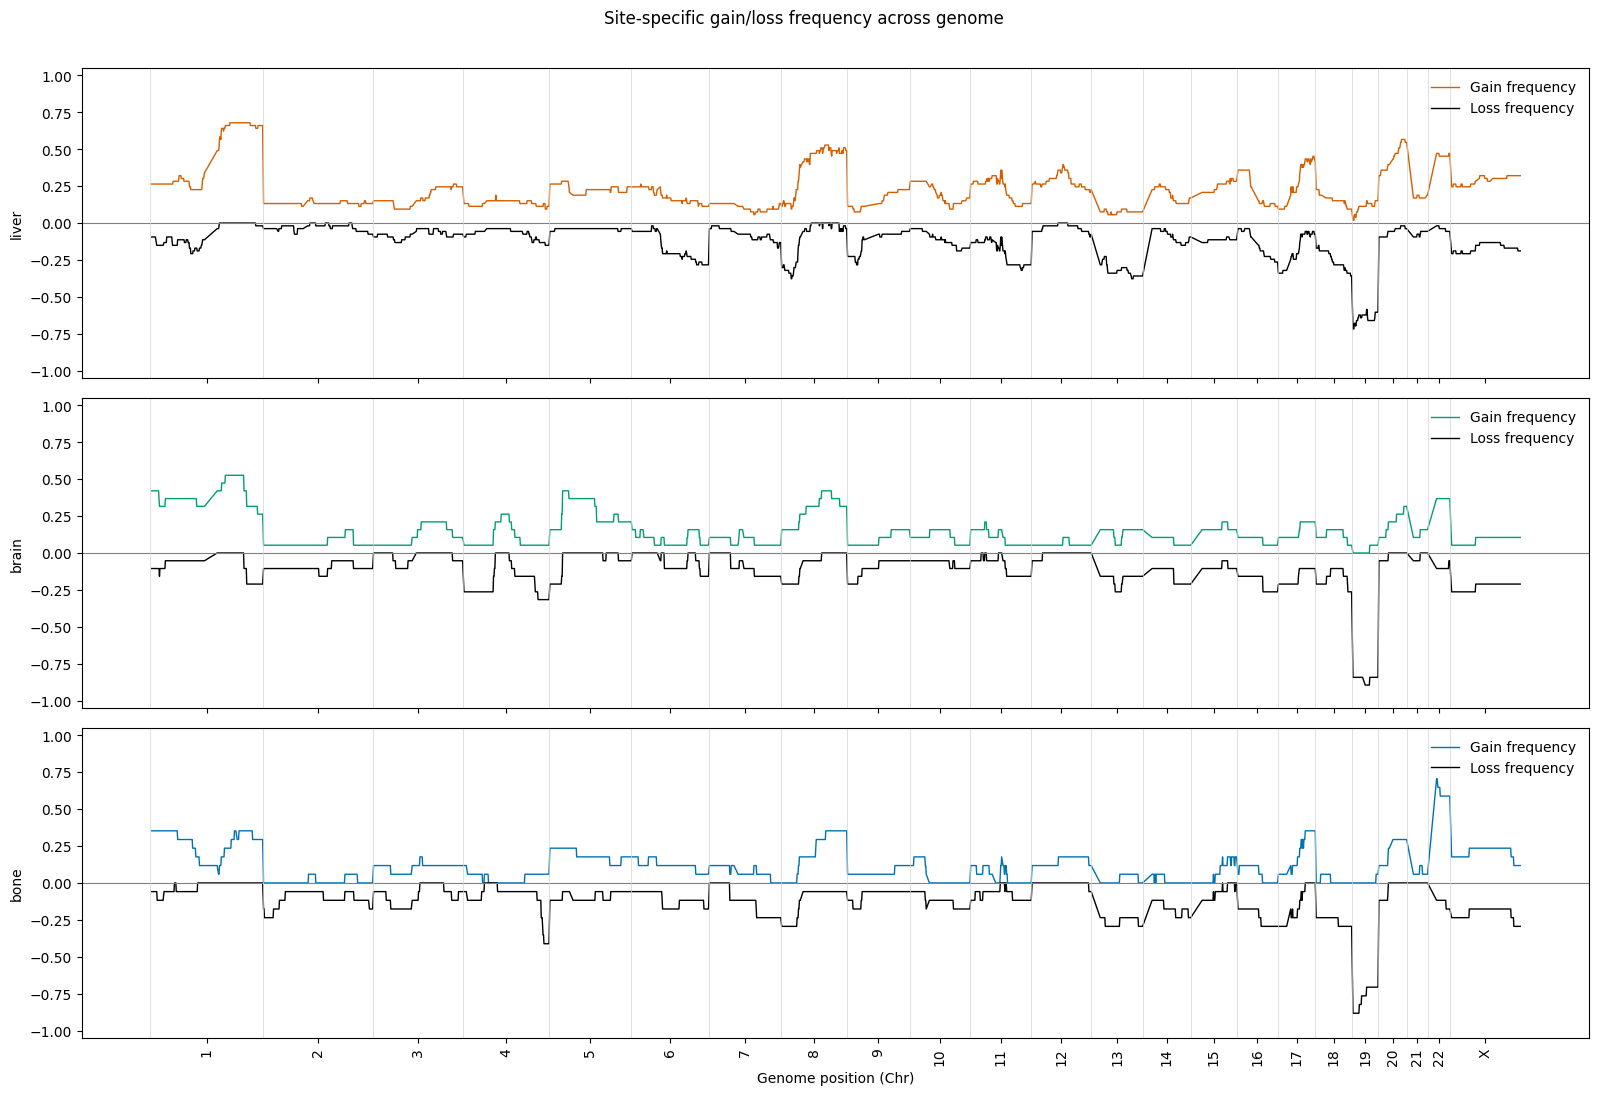


Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/site_gain_loss_frequency_across_genome.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/site_gain_loss_frequency_across_genome.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/site_gain_loss_frequency_across_genome.pdf


In [3]:
# Genome wide CNV profile
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Paths
# ============================================================
WIDE_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/combined_top3sites_1Mb_cnr_wide.tsv"
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_combinations.csv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles"

os.makedirs(OUTDIR, exist_ok=True)

OUT_PNG = os.path.join(OUTDIR, "site_gain_loss_frequency_across_genome.png")
OUT_PDF = os.path.join(OUTDIR, "site_gain_loss_frequency_across_genome.pdf")

# Optional summary table
OUT_TSV = os.path.join(OUTDIR, "site_gain_loss_frequency_across_genome.tsv")

# ============================================================
# Settings
# ============================================================
FOCUS_SITES = ["liver", "brain", "bone"]
SITE_ORDER = ["liver", "brain", "bone"]

SITE_COLORS = {
    "liver": "#D55E00",
    "brain": "#009E73",
    "bone":  "#0072B2"
}

CHR_ORDER = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

# ============================================================
# Helper functions
# ============================================================
def parse_samples_from_wide(df):
    log2_cols = [c for c in df.columns if c.endswith(".log2")]
    return sorted([c[:-5] for c in log2_cols])  # remove ".log2"

def clean_call(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().upper()

    # Gains
    if x in {"GAIN", "AMP", "HLAMP", "AMPLIFICATION"}:
        return "GAIN"

    # Losses / deletions
    if x in {"LOSS", "DEL", "HETD", "HOMD", "DELETION"}:
        return "LOSS"

    # Neutral
    if x in {"NEUT", "NEUTRAL"}:
        return "NEUTRAL"

    return x

def chromosome_sort_key(chrom):
    return CHR_ORDER.index(chrom) if chrom in CHR_ORDER else 999

# ============================================================
# Load files
# ============================================================
wide = pd.read_csv(WIDE_FILE, sep="\t")
meta = pd.read_csv(META_FILE)

meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()
meta = meta[meta["metastatic_sites"].isin(FOCUS_SITES)].copy()

sample_to_site = dict(zip(meta["id"], meta["metastatic_sites"]))

samples = parse_samples_from_wide(wide)
samples = [s for s in samples if s in sample_to_site]

print("Samples found in wide matrix and metadata:", len(samples))
print("\nSample counts by site:")
for site in SITE_ORDER:
    n = sum(sample_to_site[s] == site for s in samples)
    print(f"{site}: {n}")

# ============================================================
# Prepare genomic coordinate table
# ============================================================
plot_df = wide[["chromosome", "start", "end", "gene"]].copy()
plot_df["chromosome"] = plot_df["chromosome"].astype(str)
plot_df["start"] = pd.to_numeric(plot_df["start"], errors="coerce")
plot_df["end"] = pd.to_numeric(plot_df["end"], errors="coerce")

plot_df = plot_df.dropna(subset=["chromosome", "start", "end"]).copy()
plot_df["start"] = plot_df["start"].astype(int)
plot_df["end"] = plot_df["end"].astype(int)

plot_df = plot_df[plot_df["chromosome"].isin(CHR_ORDER)].copy()
plot_df["chr_order"] = plot_df["chromosome"].map(chromosome_sort_key)
plot_df = plot_df.sort_values(["chr_order", "start", "end"]).reset_index(drop=True)

# midpoint within chromosome
plot_df["midpoint"] = (plot_df["start"] + plot_df["end"]) / 2.0

# ============================================================
# Compute gain/loss frequency per site for each bin
# ============================================================
for site in SITE_ORDER:
    site_samples = [s for s in samples if sample_to_site[s] == site]

    if len(site_samples) == 0:
        plot_df[f"{site}_gain_freq"] = np.nan
        plot_df[f"{site}_loss_freq"] = np.nan
        plot_df[f"{site}_n_valid"] = 0
        continue

    collapsed_calls = []
    for sample in site_samples:
        call_col = f"{sample}.Corrected_Call"
        if call_col not in wide.columns:
            continue
        collapsed_calls.append(wide[call_col].apply(clean_call).rename(sample))

    if len(collapsed_calls) == 0:
        plot_df[f"{site}_gain_freq"] = np.nan
        plot_df[f"{site}_loss_freq"] = np.nan
        plot_df[f"{site}_n_valid"] = 0
        continue

    site_call_df = pd.concat(collapsed_calls, axis=1)

    valid_counts = site_call_df.notna().sum(axis=1)
    gain_counts = (site_call_df == "GAIN").sum(axis=1)
    loss_counts = (site_call_df == "LOSS").sum(axis=1)

    gain_freq = np.where(valid_counts > 0, gain_counts / valid_counts, np.nan)
    loss_freq = np.where(valid_counts > 0, loss_counts / valid_counts, np.nan)

    plot_df[f"{site}_gain_freq"] = gain_freq
    plot_df[f"{site}_loss_freq"] = loss_freq
    plot_df[f"{site}_n_valid"] = valid_counts.values

# Save summary table
plot_df.to_csv(OUT_TSV, sep="\t", index=False)

# ============================================================
# Build genome-wide x coordinates
# ============================================================
chrom_lengths = (
    plot_df.groupby("chromosome", as_index=False)["end"]
    .max()
    .sort_values("chromosome", key=lambda x: x.map(chromosome_sort_key))
)

chrom_offsets = {}
chrom_midpoints = {}
offset = 0

for _, row in chrom_lengths.iterrows():
    chrom = row["chromosome"]
    length = int(row["end"])
    chrom_offsets[chrom] = offset
    chrom_midpoints[chrom] = offset + (length / 2.0)
    offset += length

plot_df["genome_x"] = plot_df.apply(
    lambda r: chrom_offsets[r["chromosome"]] + r["midpoint"],
    axis=1
)

# ============================================================
# Plot
# ============================================================
fig, axes = plt.subplots(len(SITE_ORDER), 1, figsize=(16, 3.6 * len(SITE_ORDER)), sharex=True)

if len(SITE_ORDER) == 1:
    axes = [axes]

for ax, site in zip(axes, SITE_ORDER):
    gain_col = f"{site}_gain_freq"
    loss_col = f"{site}_loss_freq"

    ax.plot(
        plot_df["genome_x"],
        plot_df[gain_col],
        linewidth=1.0,
        color=SITE_COLORS[site],
        label="Gain frequency"
    )

    ax.plot(
        plot_df["genome_x"],
        -plot_df[loss_col],
        linewidth=1.0,
        color="black",
        label="Loss frequency"
    )

    ax.axhline(0, color="grey", linewidth=0.8)

    for chrom, start_offset in chrom_offsets.items():
        ax.axvline(start_offset, color="lightgrey", linewidth=0.5)

    ax.set_ylim(-1.05, 1.05)
    ax.set_ylabel(site)
    ax.legend(frameon=False, loc="upper right")

axes[-1].set_xticks([chrom_midpoints[c] for c in chrom_lengths["chromosome"]])
axes[-1].set_xticklabels([c.replace("chr", "") for c in chrom_lengths["chromosome"]], rotation=90)
axes[-1].set_xlabel("Genome position (Chr)")

fig.suptitle("Site-specific gain/loss frequency across genome", y=1.01)

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved files:")
print(OUT_TSV)
print(OUT_PNG)
print(OUT_PDF)

In [9]:
# Shared bin (Gain/loss) across top 3 met sites
import os
import numpy as np
import pandas as pd

# ============================================================
# Paths
# ============================================================
WIDE_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/combined_top3sites_1Mb_cnr_wide.tsv"
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_combinations.csv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles"

os.makedirs(OUTDIR, exist_ok=True)

OUT_FREQ      = os.path.join(OUTDIR, "site_event_frequency_per_bin.tsv")
OUT_GAIN_COMM = os.path.join(OUTDIR, "common_gain_bins_across_all_sites.tsv")
OUT_LOSS_COMM = os.path.join(OUTDIR, "common_loss_bins_across_all_sites.tsv")

# ============================================================
# Settings
# ============================================================
FOCUS_SITES = ["liver", "brain", "bone"]
SITE_ORDER = ["liver", "brain", "bone"]

# Common-bin threshold across all three sites
MIN_COMMON_FREQ = 0.30 # A bin must be present in at least 30% of samples in each site.

CHR_ORDER = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

# ============================================================
# Helper functions
# ============================================================
def parse_samples_from_wide(df):
    log2_cols = [c for c in df.columns if c.endswith(".log2")]
    return sorted([c[:-5] for c in log2_cols])

def clean_call(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().upper()

    if x in {"GAIN", "AMP", "HLAMP", "AMPLIFICATION"}:
        return "GAIN"

    if x in {"LOSS", "DEL", "HETD", "HOMD", "DELETION"}:
        return "LOSS"

    if x in {"NEUT", "NEUTRAL"}:
        return "NEUTRAL"

    return x

def chromosome_sort_key(chrom):
    return CHR_ORDER.index(chrom) if chrom in CHR_ORDER else 999

# ============================================================
# Load files
# ============================================================
wide = pd.read_csv(WIDE_FILE, sep="\t")
meta = pd.read_csv(META_FILE)

meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()
meta = meta[meta["metastatic_sites"].isin(FOCUS_SITES)].copy()

sample_to_site = dict(zip(meta["id"], meta["metastatic_sites"]))

samples = parse_samples_from_wide(wide)
samples = [s for s in samples if s in sample_to_site]

site_to_samples = {site: [] for site in SITE_ORDER}
for s in samples:
    site_to_samples[sample_to_site[s]].append(s)

print("Samples by site:")
for site in SITE_ORDER:
    print(f"{site}: {len(site_to_samples[site])}")

# ============================================================
# Base coordinate table
# ============================================================
freq_df = wide[["chromosome", "start", "end", "gene"]].copy()
freq_df["chromosome"] = freq_df["chromosome"].astype(str)
freq_df["start"] = pd.to_numeric(freq_df["start"], errors="coerce")
freq_df["end"] = pd.to_numeric(freq_df["end"], errors="coerce")

freq_df = freq_df.dropna(subset=["chromosome", "start", "end"]).copy()
freq_df["start"] = freq_df["start"].astype(int)
freq_df["end"] = freq_df["end"].astype(int)
freq_df["chr_order"] = freq_df["chromosome"].map(chromosome_sort_key)

# ============================================================
# Per-site gain/loss frequencies
# ============================================================
for site in SITE_ORDER:
    site_samples = site_to_samples[site]
    call_cols = [f"{s}.Corrected_Call" for s in site_samples if f"{s}.Corrected_Call" in wide.columns]

    if len(call_cols) == 0:
        freq_df[f"{site}_gain_count"] = np.nan
        freq_df[f"{site}_loss_count"] = np.nan
        freq_df[f"{site}_valid_n"] = np.nan
        freq_df[f"{site}_gain_freq"] = np.nan
        freq_df[f"{site}_loss_freq"] = np.nan
        continue

    call_block = wide[call_cols].applymap(clean_call)

    valid_n = call_block.notna().sum(axis=1)
    gain_count = (call_block == "GAIN").sum(axis=1)
    loss_count = (call_block == "LOSS").sum(axis=1)

    gain_freq = np.where(valid_n > 0, gain_count / valid_n, np.nan)
    loss_freq = np.where(valid_n > 0, loss_count / valid_n, np.nan)

    freq_df[f"{site}_gain_count"] = gain_count.values
    freq_df[f"{site}_loss_count"] = loss_count.values
    freq_df[f"{site}_valid_n"] = valid_n.values
    freq_df[f"{site}_gain_freq"] = gain_freq
    freq_df[f"{site}_loss_freq"] = loss_freq

# ============================================================
# Pooled frequencies across all selected samples
# ============================================================
all_call_cols = [f"{s}.Corrected_Call" for s in samples if f"{s}.Corrected_Call" in wide.columns]
all_call_block = wide[all_call_cols].applymap(clean_call)

all_valid_n = all_call_block.notna().sum(axis=1)
all_gain_count = (all_call_block == "GAIN").sum(axis=1)
all_loss_count = (all_call_block == "LOSS").sum(axis=1)

freq_df["all_valid_n"] = all_valid_n.values
freq_df["all_gain_count"] = all_gain_count.values
freq_df["all_loss_count"] = all_loss_count.values
freq_df["all_gain_freq"] = np.where(all_valid_n > 0, all_gain_count / all_valid_n, np.nan)
freq_df["all_loss_freq"] = np.where(all_valid_n > 0, all_loss_count / all_valid_n, np.nan)

# ============================================================
# Shared/common bins across all 3 sites
# ============================================================
freq_df["common_gain_all_sites"] = (
    freq_df["liver_gain_freq"].ge(MIN_COMMON_FREQ) &
    freq_df["brain_gain_freq"].ge(MIN_COMMON_FREQ) &
    freq_df["bone_gain_freq"].ge(MIN_COMMON_FREQ)
)

freq_df["common_loss_all_sites"] = (
    freq_df["liver_loss_freq"].ge(MIN_COMMON_FREQ) &
    freq_df["brain_loss_freq"].ge(MIN_COMMON_FREQ) &
    freq_df["bone_loss_freq"].ge(MIN_COMMON_FREQ)
)

# Extra ranking summaries
freq_df["min_gain_freq_across_sites"] = freq_df[
    ["liver_gain_freq", "brain_gain_freq", "bone_gain_freq"]
].min(axis=1)

freq_df["min_loss_freq_across_sites"] = freq_df[
    ["liver_loss_freq", "brain_loss_freq", "bone_loss_freq"]
].min(axis=1)

freq_df["mean_gain_freq_across_sites"] = freq_df[
    ["liver_gain_freq", "brain_gain_freq", "bone_gain_freq"]
].mean(axis=1)

freq_df["mean_loss_freq_across_sites"] = freq_df[
    ["liver_loss_freq", "brain_loss_freq", "bone_loss_freq"]
].mean(axis=1)

# ============================================================
# Save full frequency table
# ============================================================
freq_df = freq_df.sort_values(["chr_order", "start", "end"]).reset_index(drop=True)
freq_df.to_csv(OUT_FREQ, sep="\t", index=False)

# ============================================================
# Save common gain bins
# ============================================================
common_gain = freq_df[freq_df["common_gain_all_sites"]].copy()
common_gain = common_gain.sort_values(
    ["min_gain_freq_across_sites", "mean_gain_freq_across_sites", "all_gain_freq"],
    ascending=[False, False, False]
).reset_index(drop=True)

common_gain.to_csv(OUT_GAIN_COMM, sep="\t", index=False)

# ============================================================
# Save common loss bins
# ============================================================
common_loss = freq_df[freq_df["common_loss_all_sites"]].copy()
common_loss = common_loss.sort_values(
    ["min_loss_freq_across_sites", "mean_loss_freq_across_sites", "all_loss_freq"],
    ascending=[False, False, False]
).reset_index(drop=True)

common_loss.to_csv(OUT_LOSS_COMM, sep="\t", index=False)

# ============================================================
# Print summary
# ============================================================
print(f"\nCommon gain bins across all 3 sites (freq >= {MIN_COMMON_FREQ} in each site): {len(common_gain)}")
if len(common_gain) > 0:
    print(common_gain[
        ["chromosome", "start", "end", "gene",
         "liver_gain_freq", "brain_gain_freq", "bone_gain_freq",
         "min_gain_freq_across_sites", "mean_gain_freq_across_sites"]
    ].head(15).to_string(index=False))

print(f"\nCommon loss bins across all 3 sites (freq >= {MIN_COMMON_FREQ} in each site): {len(common_loss)}")
if len(common_loss) > 0:
    print(common_loss[
        ["chromosome", "start", "end", "gene",
         "liver_loss_freq", "brain_loss_freq", "bone_loss_freq",
         "min_loss_freq_across_sites", "mean_loss_freq_across_sites"]
    ].head(15).to_string(index=False))

print("\nSaved files:")
print(OUT_FREQ)
print(OUT_GAIN_COMM)
print(OUT_LOSS_COMM)

Samples by site:
liver: 53
brain: 19
bone: 17

Common gain bins across all 3 sites (freq >= 0.3 in each site): 109
chromosome    start      end                                                                                                                                                                                                                                                gene  liver_gain_freq  brain_gain_freq  bone_gain_freq  min_gain_freq_across_sites  mean_gain_freq_across_sites
     chr22 19000001 20000000                                                                    DGCR5,DGCR2,DGCR11,ESS2,TSSK2,GSC2,LINC01311,SLC25A1,CLTCL1,HIRA,MRPL40,C22orf39,UFD1,CDC45,CLDN5,LINC00895,SEPTIN5,SEPT5-GP1BB,GP1BB,TBX1,GNB1L,RTL10,TXNRD2,COMT,MIR4761,ARVCF         0.471698         0.368421        0.705882                    0.368421                     0.515334
     chr22 20000001 21000000        ARVCF,TANGO2,MIR185,DGCR8,MIR3618,MIR1306,TRMT2A,MIR6816,RANBP1,SNORA77B,ZDHHC8,CCDC188,L

In [4]:
# Significant gain/loss enriched bin by sites
import os
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

# ============================================================
# Paths
# ============================================================
WIDE_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/combined_top3sites_1Mb_cnr_wide.tsv"
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_combinations.csv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles"

os.makedirs(OUTDIR, exist_ok=True)

OUT_GAIN_ALL  = os.path.join(OUTDIR, "bin_site_gain_enrichment_stats.tsv")
OUT_LOSS_ALL  = os.path.join(OUTDIR, "bin_site_loss_enrichment_stats.tsv")
OUT_GAIN_SIG  = os.path.join(OUTDIR, "significant_gain_bins_by_site.tsv")
OUT_LOSS_SIG  = os.path.join(OUTDIR, "significant_loss_bins_by_site.tsv")

# ============================================================
# Settings
# ============================================================
FOCUS_SITES = ["liver", "brain", "bone"]
SITE_ORDER = ["liver", "brain", "bone"]

# significance / biological filters
FDR_CUTOFF = 0.05
MIN_FREQ_DIFF = 0.10          # site_freq - other_freq must be at least this much
MIN_SITE_EVENT_COUNT = 2      # at least this many event-positive samples in that site

# ============================================================
# Helper functions
# ============================================================
def parse_samples_from_wide(df):
    log2_cols = [c for c in df.columns if c.endswith(".log2")]
    return sorted([c[:-5] for c in log2_cols])  # remove ".log2"

def bh_adjust(pvals):
    """Benjamini-Hochberg FDR correction."""
    pvals = np.asarray(pvals, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]

    adj = np.empty(n, dtype=float)
    prev = 1.0
    for i in range(n - 1, -1, -1):
        rank = i + 1
        val = ranked[i] * n / rank
        prev = min(prev, val)
        adj[i] = prev

    out = np.empty(n, dtype=float)
    out[order] = np.minimum(adj, 1.0)
    return out

def clean_call(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().upper()

    # gains
    if x in {"GAIN", "AMP", "HLAMP", "AMPLIFICATION"}:
        return "GAIN"

    # losses / deletions
    if x in {"LOSS", "DEL", "HETD", "HOMD", "DELETION"}:
        return "LOSS"

    # neutral
    if x in {"NEUT", "NEUTRAL"}:
        return "NEUTRAL"

    return x

def collapse_call_block(df):
    """Apply clean_call to every column in a call matrix."""
    out = df.copy()
    for col in out.columns:
        out[col] = out[col].map(clean_call)
    return out

def run_site_enrichment(wide, site_to_samples, site_order, event_type):
    """
    event_type: 'GAIN' or 'LOSS'
    Returns one combined stats table across all sites.
    """
    all_site_rows = []

    coord_df = wide[["chromosome", "start", "end", "gene"]].copy()

    for site in site_order:
        site_samples = site_to_samples.get(site, [])
        other_samples = [s for s in sum([site_to_samples.get(x, []) for x in site_order], []) if s != site]
        # fix above line: variable naming issue handled below
        other_samples = []
        for s2 in site_order:
            if s2 != site:
                other_samples.extend(site_to_samples.get(s2, []))

        site_call_cols = [f"{s}.Corrected_Call" for s in site_samples if f"{s}.Corrected_Call" in wide.columns]
        other_call_cols = [f"{s}.Corrected_Call" for s in other_samples if f"{s}.Corrected_Call" in wide.columns]

        if len(site_call_cols) == 0 or len(other_call_cols) == 0:
            print(f"[WARN] Skipping {site} for {event_type}: insufficient call columns")
            continue

        site_calls = collapse_call_block(wide[site_call_cols])
        other_calls = collapse_call_block(wide[other_call_cols])

        # per-bin counts
        site_valid = site_calls.notna().sum(axis=1)
        other_valid = other_calls.notna().sum(axis=1)

        site_event = (site_calls == event_type).sum(axis=1)
        other_event = (other_calls == event_type).sum(axis=1)

        site_non_event = site_valid - site_event
        other_non_event = other_valid - other_event

        rows = []
        for i in range(len(wide)):
            a = int(site_event.iloc[i])       # site event count
            b = int(site_non_event.iloc[i])   # site not-event count
            c = int(other_event.iloc[i])      # other event count
            d = int(other_non_event.iloc[i])  # other not-event count

            site_total = a + b
            other_total = c + d

            if site_total == 0 or other_total == 0:
                odds_ratio = np.nan
                p_value = np.nan
                site_freq = np.nan
                other_freq = np.nan
                freq_diff = np.nan
                note = "missing_valid_calls"
            else:
                site_freq = a / site_total
                other_freq = c / other_total
                freq_diff = site_freq - other_freq

                # one-sided test: enriched in this site vs the rest
                odds_ratio, p_value = fisher_exact([[a, b], [c, d]], alternative="greater")
                note = "ok"

            rows.append({
                "chromosome": coord_df.iloc[i]["chromosome"],
                "start": int(coord_df.iloc[i]["start"]),
                "end": int(coord_df.iloc[i]["end"]),
                "gene": coord_df.iloc[i]["gene"],
                "site": site,
                "event_type": event_type,
                "site_event_count": a,
                "site_non_event_count": b,
                "site_total_valid": site_total,
                "other_event_count": c,
                "other_non_event_count": d,
                "other_total_valid": other_total,
                "site_event_freq": site_freq,
                "other_event_freq": other_freq,
                "freq_diff": freq_diff,
                "odds_ratio": odds_ratio,
                "p_value": p_value,
                "note": note
            })

        site_df = pd.DataFrame(rows)

        # BH correction within this site across all bins
        valid_mask = site_df["p_value"].notna()
        site_df["p_adj_bh"] = np.nan
        if valid_mask.sum() > 0:
            site_df.loc[valid_mask, "p_adj_bh"] = bh_adjust(site_df.loc[valid_mask, "p_value"].values)

        # significance flag
        site_df["significant"] = (
            site_df["p_adj_bh"].lt(FDR_CUTOFF) &
            site_df["odds_ratio"].gt(1) &
            site_df["freq_diff"].ge(MIN_FREQ_DIFF) &
            site_df["site_event_count"].ge(MIN_SITE_EVENT_COUNT)
        )

        all_site_rows.append(site_df)

    if len(all_site_rows) == 0:
        return pd.DataFrame()

    out_df = pd.concat(all_site_rows, ignore_index=True)
    out_df = out_df.sort_values(["site", "chromosome", "start", "end"]).reset_index(drop=True)
    return out_df

# ============================================================
# Load files
# ============================================================
wide = pd.read_csv(WIDE_FILE, sep="\t")
meta = pd.read_csv(META_FILE)

meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()
meta = meta[meta["metastatic_sites"].isin(FOCUS_SITES)].copy()

sample_to_site = dict(zip(meta["id"], meta["metastatic_sites"]))

samples = parse_samples_from_wide(wide)
samples = [s for s in samples if s in sample_to_site]

# build site -> samples mapping
site_to_samples = {site: [] for site in SITE_ORDER}
for s in samples:
    site = sample_to_site[s]
    if site in site_to_samples:
        site_to_samples[site].append(s)

print("Samples used by site:")
for site in SITE_ORDER:
    print(f"{site}: {len(site_to_samples[site])}")

# ============================================================
# Gain enrichment
# ============================================================
gain_df = run_site_enrichment(
    wide=wide,
    site_to_samples=site_to_samples,
    site_order=SITE_ORDER,
    event_type="GAIN"
)

gain_df.to_csv(OUT_GAIN_ALL, sep="\t", index=False)

gain_sig = gain_df[gain_df["significant"]].copy()
gain_sig = gain_sig.sort_values(
    ["site", "p_adj_bh", "freq_diff", "odds_ratio"],
    ascending=[True, True, False, False]
).reset_index(drop=True)
gain_sig.to_csv(OUT_GAIN_SIG, sep="\t", index=False)

# ============================================================
# Loss enrichment
# ============================================================
loss_df = run_site_enrichment(
    wide=wide,
    site_to_samples=site_to_samples,
    site_order=SITE_ORDER,
    event_type="LOSS"
)

loss_df.to_csv(OUT_LOSS_ALL, sep="\t", index=False)

loss_sig = loss_df[loss_df["significant"]].copy()
loss_sig = loss_sig.sort_values(
    ["site", "p_adj_bh", "freq_diff", "odds_ratio"],
    ascending=[True, True, False, False]
).reset_index(drop=True)
loss_sig.to_csv(OUT_LOSS_SIG, sep="\t", index=False)

# ============================================================
# Print summary
# ============================================================
print("\nSignificant gain-enriched bins by site:")
if len(gain_sig) == 0:
    print("None")
else:
    print(gain_sig.groupby("site").size())

print("\nSignificant loss-enriched bins by site:")
if len(loss_sig) == 0:
    print("None")
else:
    print(loss_sig.groupby("site").size())

print("\nTop gain-enriched bins:")
if len(gain_sig) > 0:
    print(
        gain_sig[[
            "chromosome", "start", "end", "gene", "site",
            "site_event_freq", "other_event_freq",
            "freq_diff", "odds_ratio", "p_adj_bh"
        ]].head(15).to_string(index=False)
    )
else:
    print("None")

print("\nTop loss-enriched bins:")
if len(loss_sig) > 0:
    print(
        loss_sig[[
            "chromosome", "start", "end", "gene", "site",
            "site_event_freq", "other_event_freq",
            "freq_diff", "odds_ratio", "p_adj_bh"
        ]].head(15).to_string(index=False)
    )
else:
    print("None")

print("\nSaved files:")
print(OUT_GAIN_ALL)
print(OUT_LOSS_ALL)
print(OUT_GAIN_SIG)
print(OUT_LOSS_SIG)

Samples used by site:
liver: 53
brain: 19
bone: 17

Significant gain-enriched bins by site:
None

Significant loss-enriched bins by site:
None

Top gain-enriched bins:
None

Top loss-enriched bins:
None

Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/bin_site_gain_enrichment_stats.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/bin_site_loss_enrichment_stats.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/significant_gain_bins_by_site.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/significant_loss_bins_by_site.tsv


In [14]:
# For each 100 kb fragmentation bin, map it to its parent 1 Mb CNV bin, then use the CNV frequencies of the matched site (site_highest) to assign one of 4 states.
# MIXED: g >= 0.20 and l >= 0.20
# GAIN: g >= 0.30 and l < 0.20
# LOSS: l >= 0.30 and g < 0.20
# NEUTRAL: everything else

import os
import numpy as np
import pandas as pd

# ============================================================
# Paths
# ============================================================
FRAG_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Regional_Fragment_analysis/LOLA_inputs_top3sites/Effect_size/KW_BH/KW_BH.universe50.BHsig.with_site_direction.with_genes.tsv"

CNV_FREQ_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/site_event_frequency_per_bin.tsv"

OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles"
os.makedirs(OUTDIR, exist_ok=True)

OUT_FINAL = os.path.join(
    OUTDIR,
    "fragmentation_BHsig_bins_with_matched_1Mb_CNV_state.tsv"
)

OUT_SUMMARY = os.path.join(
    OUTDIR,
    "fragmentation_BHsig_bins_with_matched_1Mb_CNV_state_summary.tsv"
)

OUT_UNMAPPED = os.path.join(
    OUTDIR,
    "fragmentation_BHsig_bins_unmapped_to_1Mb_CNV.tsv"
)

# ============================================================
# Settings
# ============================================================
TARGET_SITES = ["liver", "brain", "bone"]   # change if you only want liver/bone

EVENT_THRESHOLD = 0.30   # call strong gain/loss
MIX_THRESHOLD = 0.20     # if both gain and loss are >= 0.20 -> MIXED

CHR_ORDER = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

# ============================================================
# Helper functions
# ============================================================
def chromosome_sort_key(chrom):
    return CHR_ORDER.index(chrom) if chrom in CHR_ORDER else 999

def parse_bin_id(bin_id):
    # example: chr3_171800000_171900000
    parts = str(bin_id).strip().split("_")
    if len(parts) != 3:
        raise ValueError(f"Unexpected bin_id format: {bin_id}")
    chrom, start, end = parts[0], int(parts[1]), int(parts[2])
    return chrom, start, end

def safe_numeric(series):
    return pd.to_numeric(series, errors="coerce")

def get_matched_value(row, suffix):
    site = row["fragment_site"]
    col = f"{site}_{suffix}"
    return row.get(col, np.nan)

def classify_matched_state(g, l):
    if pd.isna(g) or pd.isna(l):
        return np.nan

    # both gain and loss are non-trivial
    if g >= MIX_THRESHOLD and l >= MIX_THRESHOLD:
        return "MIXED"

    # recurrent gain
    if g >= EVENT_THRESHOLD and l < MIX_THRESHOLD:
        return "GAIN"

    # recurrent loss
    if l >= EVENT_THRESHOLD and g < MIX_THRESHOLD:
        return "LOSS"

    # no strong recurrent CNV pattern
    return "NEUTRAL"

# ============================================================
# Load fragmentation file
# ============================================================
frag = pd.read_csv(FRAG_FILE, sep="\t")

required_frag_cols = [
    "bin_id", "eta2", "rank_eta2", "kw_H", "kw_p", "kw_q_BH",
    "n_liver", "n_brain", "n_bone", "universe_pct",
    "median_liver", "median_brain", "median_bone",
    "site_highest", "site_lowest", "delta_high_low", "delta_top2", "genes"
]
missing_frag = [c for c in required_frag_cols if c not in frag.columns]
if missing_frag:
    raise ValueError(f"Missing required fragmentation columns: {missing_frag}")

frag = frag[frag["site_highest"].isin(TARGET_SITES)].copy()

parsed = frag["bin_id"].apply(parse_bin_id)
frag["frag_chromosome"] = parsed.map(lambda x: x[0])
frag["frag_start"] = parsed.map(lambda x: x[1])
frag["frag_end"] = parsed.map(lambda x: x[2])

frag["fragment_site"] = frag["site_highest"]
frag["frag_genes"] = frag["genes"]

# ============================================================
# Load CNV frequency file
# ============================================================
cnv = pd.read_csv(CNV_FREQ_FILE, sep="\t")

required_cnv_cols = [
    "chromosome", "start", "end", "gene",
    "liver_gain_freq", "liver_loss_freq",
    "brain_gain_freq", "brain_loss_freq",
    "bone_gain_freq", "bone_loss_freq"
]
missing_cnv = [c for c in required_cnv_cols if c not in cnv.columns]
if missing_cnv:
    raise ValueError(f"Missing required CNV columns: {missing_cnv}")

cnv["chromosome"] = cnv["chromosome"].astype(str)
cnv["start"] = safe_numeric(cnv["start"])
cnv["end"] = safe_numeric(cnv["end"])
cnv = cnv.dropna(subset=["chromosome", "start", "end"]).copy()
cnv["start"] = cnv["start"].astype(int)
cnv["end"] = cnv["end"].astype(int)

# ============================================================
# Map 100 kb fragmentation bins to parent 1 Mb CNV bins
# ============================================================
merged = frag.merge(
    cnv,
    left_on="frag_chromosome",
    right_on="chromosome",
    how="left"
)

mapped = merged[
    (merged["frag_start"] >= merged["start"]) &
    (merged["frag_end"] <= merged["end"])
].copy()

mapped_bin_ids = set(mapped["bin_id"].astype(str))
unmapped = frag[~frag["bin_id"].astype(str).isin(mapped_bin_ids)].copy()

# If a bin maps more than once, keep all and report it
dup_check = mapped.groupby("bin_id").size()
n_multi = int((dup_check > 1).sum())
if n_multi > 0:
    print(f"[WARN] {n_multi} bins mapped to more than one 1 Mb CNV interval.")

# ============================================================
# Matched-site CNV annotation
# ============================================================
mapped["matched_site_gain_freq"] = mapped.apply(lambda r: get_matched_value(r, "gain_freq"), axis=1)
mapped["matched_site_loss_freq"] = mapped.apply(lambda r: get_matched_value(r, "loss_freq"), axis=1)

mapped["matched_site_CNV_state"] = [
    classify_matched_state(g, l)
    for g, l in zip(mapped["matched_site_gain_freq"], mapped["matched_site_loss_freq"])
]

# optional neutral frequency for reference only
mapped["matched_site_neutral_freq"] = 1 - mapped["matched_site_gain_freq"] - mapped["matched_site_loss_freq"]
mapped["matched_site_neutral_freq"] = np.clip(mapped["matched_site_neutral_freq"], 0, 1)

# ============================================================
# Keep a clean final column set
# ============================================================
keep_cols = [
    "fragment_site",
    "bin_id",
    "eta2",
    "rank_eta2",
    "kw_H",
    "kw_p",
    "kw_q_BH",
    "median_liver",
    "median_brain",
    "median_bone",
    "site_highest",
    "site_lowest",
    "delta_high_low",
    "delta_top2",
    "frag_genes",
    "frag_chromosome",
    "frag_start",
    "frag_end",

    # parent 1 Mb CNV region
    "chromosome",
    "start",
    "end",
    "gene",

    # all site CNV frequencies for context
    "liver_gain_freq",
    "liver_loss_freq",
    "brain_gain_freq",
    "brain_loss_freq",
    "bone_gain_freq",
    "bone_loss_freq",

    # matched-site interpretation
    "matched_site_gain_freq",
    "matched_site_loss_freq",
    "matched_site_neutral_freq",
    "matched_site_CNV_state"
]

keep_cols = [c for c in keep_cols if c in mapped.columns]
final_df = mapped[keep_cols].copy()

final_df["chr_order"] = final_df["frag_chromosome"].map(chromosome_sort_key)
final_df = final_df.sort_values(
    ["fragment_site", "chr_order", "frag_start", "frag_end"],
    ascending=[True, True, True, True]
).drop(columns=["chr_order"], errors="ignore").reset_index(drop=True)

# ============================================================
# Save final file
# ============================================================
final_df.to_csv(OUT_FINAL, sep="\t", index=False)

if len(unmapped) > 0:
    unmapped.to_csv(OUT_UNMAPPED, sep="\t", index=False)

# ============================================================
# Summary
# ============================================================
summary = (
    final_df.groupby(["fragment_site", "matched_site_CNV_state"])
            .size()
            .reset_index(name="n_bins")
            .sort_values(["fragment_site", "n_bins"], ascending=[True, False])
)

summary.to_csv(OUT_SUMMARY, sep="\t", index=False)

# ============================================================
# Print summary
# ============================================================
print("\nInput BH-significant fragmentation bins kept:")
print(frag["fragment_site"].value_counts())

print("\nMapped bins:")
print(final_df["fragment_site"].value_counts())

if len(unmapped) > 0:
    print("\nUnmapped bins:")
    print(unmapped["fragment_site"].value_counts())

print("\nMatched-site CNV state summary:")
print(summary.to_string(index=False))

print("\nPreview of final table:")
preview_cols = [
    c for c in [
        "fragment_site", "bin_id", "eta2", "frag_genes",
        "matched_site_gain_freq", "matched_site_loss_freq",
        "matched_site_neutral_freq", "matched_site_CNV_state"
    ] if c in final_df.columns
]
print(final_df[preview_cols].head(10).to_string(index=False))

print("\nSaved files:")
print(OUT_FINAL)
print(OUT_SUMMARY)
if len(unmapped) > 0:
    print(OUT_UNMAPPED)


Input BH-significant fragmentation bins kept:
liver    872
bone     114
Name: fragment_site, dtype: int64

Mapped bins:
liver    734
bone      89
Name: fragment_site, dtype: int64

Unmapped bins:
liver    138
bone      25
Name: fragment_site, dtype: int64

Matched-site CNV state summary:
fragment_site matched_site_CNV_state  n_bins
         bone                NEUTRAL      88
         bone                   LOSS       1
        liver                NEUTRAL     629
        liver                   GAIN      64
        liver                   LOSS      32
        liver                  MIXED       9

Preview of final table:
fragment_site                   bin_id     eta2                                           frag_genes  matched_site_gain_freq  matched_site_loss_freq  matched_site_neutral_freq matched_site_CNV_state
         bone chr1_114900000_115000000 0.093409                                               TRIM33                0.117647                0.000000                   0.88

Samples found in wide matrix and metadata: 89

Sample counts by site:
liver: 53
brain: 19
bone: 17

Bins retained after missingness filter: 2469
Using top 500 variable bins for PCA

Explained variance:
PC1: 51.84%
PC2: 11.82%


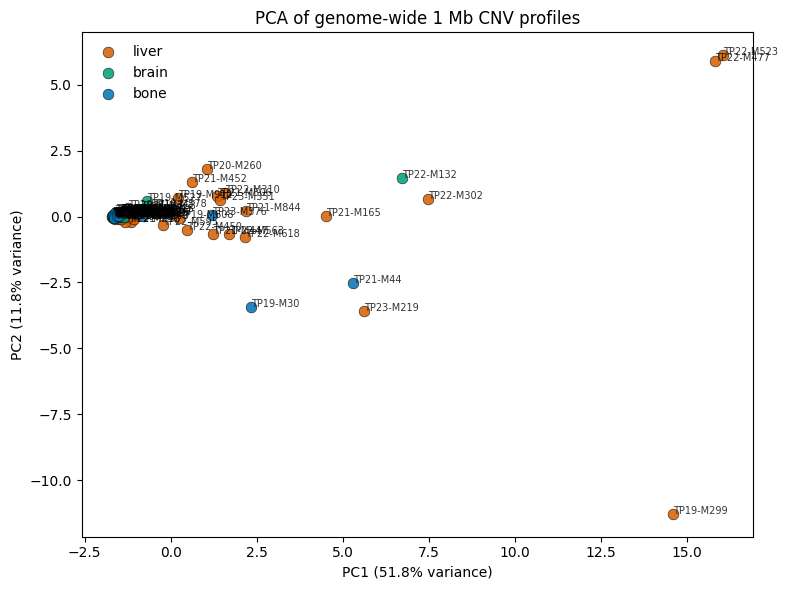


Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/CNV_PCA_top_variable_bins.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/CNV_PCA_top_variable_bins.pdf
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/CNV_PCA_sample_coordinates.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/CNV_PCA_selected_bins.tsv


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Paths
# ============================================================
WIDE_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/combined_top3sites_1Mb_cnr_wide.tsv"
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_combinations.csv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles"

os.makedirs(OUTDIR, exist_ok=True)

OUT_PNG = os.path.join(OUTDIR, "CNV_PCA_top_variable_bins.png")
OUT_PDF = os.path.join(OUTDIR, "CNV_PCA_top_variable_bins.pdf")
OUT_COORD = os.path.join(OUTDIR, "CNV_PCA_sample_coordinates.tsv")
OUT_BINS = os.path.join(OUTDIR, "CNV_PCA_selected_bins.tsv")

# ============================================================
# Settings
# ============================================================
FOCUS_SITES = ["liver", "brain", "bone"]
SITE_ORDER = ["liver", "brain", "bone"]

SITE_COLORS = {
    "liver": "#D55E00",
    "brain": "#009E73",
    "bone":  "#0072B2"
}

CHR_ORDER = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

EXCLUDE_SEX_CHR = True
USE_TOP_VARIABLE_BINS = True
TOP_N_BINS = 500
MIN_NON_MISSING_FRAC = 0.80
LABEL_POINTS = True

# ============================================================
# Helper functions
# ============================================================
def parse_samples_from_wide(df):
    log2_cols = [c for c in df.columns if c.endswith(".log2")]
    return sorted([c[:-5] for c in log2_cols])  # remove ".log2"

def chromosome_sort_key(chrom):
    return CHR_ORDER.index(chrom) if chrom in CHR_ORDER else 999

def run_pca_numpy(X, n_components=2):
    """
    PCA using NumPy SVD.
    X shape: samples x features
    Returns:
        scores: samples x n_components
        explained_variance_ratio: length n_components
    """
    X = np.asarray(X, dtype=float)

    # center features
    X_centered = X - X.mean(axis=0, keepdims=True)

    # SVD
    U, S, VT = np.linalg.svd(X_centered, full_matrices=False)

    # sample scores
    scores = U[:, :n_components] * S[:n_components]

    # explained variance
    n_samples = X.shape[0]
    explained_variance = (S ** 2) / (n_samples - 1)
    total_variance = explained_variance.sum()
    explained_variance_ratio = explained_variance[:n_components] / total_variance

    return scores, explained_variance_ratio

# ============================================================
# Load files
# ============================================================
wide = pd.read_csv(WIDE_FILE, sep="\t")
meta = pd.read_csv(META_FILE)

meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()
meta = meta[meta["metastatic_sites"].isin(FOCUS_SITES)].copy()

sample_to_site = dict(zip(meta["id"], meta["metastatic_sites"]))

samples = parse_samples_from_wide(wide)
samples = [s for s in samples if s in sample_to_site]

print("Samples found in wide matrix and metadata:", len(samples))
print("\nSample counts by site:")
for site in SITE_ORDER:
    n = sum(sample_to_site[s] == site for s in samples)
    print(f"{site}: {n}")

# ============================================================
# Build bin x sample log2 matrix
# ============================================================
log2_cols = [f"{s}.log2" for s in samples if f"{s}.log2" in wide.columns]

bin_df = wide[["chromosome", "start", "end", "gene"] + log2_cols].copy()
bin_df["chromosome"] = bin_df["chromosome"].astype(str)
bin_df["start"] = pd.to_numeric(bin_df["start"], errors="coerce")
bin_df["end"] = pd.to_numeric(bin_df["end"], errors="coerce")

for col in log2_cols:
    bin_df[col] = pd.to_numeric(bin_df[col], errors="coerce")

bin_df = bin_df.dropna(subset=["chromosome", "start", "end"]).copy()
bin_df["start"] = bin_df["start"].astype(int)
bin_df["end"] = bin_df["end"].astype(int)

# Keep canonical chromosomes
bin_df = bin_df[bin_df["chromosome"].isin(CHR_ORDER)].copy()

# Exclude sex chromosomes if requested
if EXCLUDE_SEX_CHR:
    autosomes = [f"chr{i}" for i in range(1, 23)]
    bin_df = bin_df[bin_df["chromosome"].isin(autosomes)].copy()

# Sort
bin_df["chr_order"] = bin_df["chromosome"].map(chromosome_sort_key)
bin_df = bin_df.sort_values(["chr_order", "start", "end"]).reset_index(drop=True)

# ============================================================
# Filter bins by missingness
# ============================================================
non_missing_frac = bin_df[log2_cols].notna().mean(axis=1)
bin_df = bin_df[non_missing_frac >= MIN_NON_MISSING_FRAC].copy()

print("\nBins retained after missingness filter:", bin_df.shape[0])

# ============================================================
# Select top variable bins
# ============================================================
bin_df["variance_across_samples"] = np.nanvar(bin_df[log2_cols].values, axis=1)

if USE_TOP_VARIABLE_BINS:
    n_keep = min(TOP_N_BINS, bin_df.shape[0])
    bin_df = bin_df.sort_values("variance_across_samples", ascending=False).head(n_keep).copy()
    print(f"Using top {n_keep} variable bins for PCA")
else:
    print("Using all retained bins for PCA")

# Save selected bins
selected_bins = bin_df[[
    "chromosome", "start", "end", "gene", "variance_across_samples"
]].copy()
selected_bins = selected_bins.sort_values(
    ["variance_across_samples", "chromosome", "start"],
    ascending=[False, True, True]
)
selected_bins.to_csv(OUT_BINS, sep="\t", index=False)

# ============================================================
# Prepare PCA matrix: samples x bins
# ============================================================
# Current shape: bins x samples
mat = bin_df[log2_cols].copy()

# Impute missing values within each bin using bin mean across samples
row_means = mat.mean(axis=1)
mat = mat.T.fillna(row_means).T

# Final matrix for PCA: samples x bins
X = mat.T.values
sample_names = [c.replace(".log2", "") for c in mat.columns]

# ============================================================
# PCA with NumPy
# ============================================================
scores, evr = run_pca_numpy(X, n_components=2)

pc_df = pd.DataFrame({
    "sample": sample_names,
    "site": [sample_to_site[s] for s in sample_names],
    "PC1": scores[:, 0],
    "PC2": scores[:, 1]
})

pc_df["site"] = pd.Categorical(pc_df["site"], categories=SITE_ORDER, ordered=True)
pc_df = pc_df.sort_values(["site", "sample"]).reset_index(drop=True)
pc_df.to_csv(OUT_COORD, sep="\t", index=False)

pc1_var = evr[0] * 100
pc2_var = evr[1] * 100

print("\nExplained variance:")
print(f"PC1: {pc1_var:.2f}%")
print(f"PC2: {pc2_var:.2f}%")

# ============================================================
# Plot
# ============================================================
fig, ax = plt.subplots(figsize=(8, 6))

for site in SITE_ORDER:
    sub = pc_df[pc_df["site"] == site]
    if len(sub) == 0:
        continue

    ax.scatter(
        sub["PC1"],
        sub["PC2"],
        s=60,
        alpha=0.85,
        color=SITE_COLORS[site],
        edgecolor="black",
        linewidth=0.4,
        label=site
    )

    if LABEL_POINTS:
        for _, row in sub.iterrows():
            ax.text(
                row["PC1"],
                row["PC2"],
                row["sample"],
                fontsize=7,
                alpha=0.8
            )

ax.set_xlabel(f"PC1 ({pc1_var:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pc2_var:.1f}% variance)")
ax.set_title("PCA of genome-wide 1 Mb CNV profiles")
ax.legend(frameon=False)

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved files:")
print(OUT_PNG)
print(OUT_PDF)
print(OUT_COORD)
print(OUT_BINS)